# Black-Litterman Portfolio with LSTM + SVR Investor's Views

**Architecture B** — one multi-output LSTM per stock (predicts all 8 indicators at once),
then an SVR decodes the predicted indicators into a price forecast. The forecast becomes
the Black-Litterman view (Q), and the model's error sets the view's uncertainty (Ω).

```
yfinance OHLCV → 8 indicators → 30-day windows
   → LSTM (1 per stock, 8 outputs) → SVR (indicators → price)
   → views Q + Ω → Black-Litterman w*  → backtest vs SPY
```

This notebook **reuses the verified `bl_lstm_views/src` modules** (so the heavy logic is
tested), and keeps the project's two refinements over the raw design doc:

- **Stationary price target** — the SVR predicts `close / SMA₃₀(close) − 1`, not the raw
  price level, so an RBF model can't be wrecked by the 2010→2025 price trend.
- **Long-only + capped, renormalised weights** and the **no-views ⇒ w\*=w_mkt** identity.

> Research scaffold, **not** a profitable strategy — backtest numbers are illustrative.
> See `README.md` for the full caveats.

In [1]:
# Fresh setup:  pip install -r requirements.txt   (numpy pandas scikit-learn yfinance torch)
import os, sys, warnings, json
warnings.filterwarnings("ignore")
import numpy as np
import pandas as pd
import torch

sys.path.insert(0, os.getcwd())          # run this notebook from the bl_lstm_views/ folder
from src import constants as C
from src import fetch_data, black_litterman as bl
from src.indicators import add_indicators
from src.preprocessing import build_stock_dataset
from src.lstm_model import LSTMRegressor, get_device, train_stock_model, predict_indicators
from src.svr_model import train_close_svr, predict_price, train_fit_mse
from src.views import compose_view, assemble_package, write_views_json
from src.backtest import run_backtest

TICKERS    = ["AAPL", "MSFT", "AMZN", "TSLA", "META", 'WMT', 'COST', 'NVDA', "AVGO", 'ASML']
EPOCHS     = 400
MIN_WEIGHT = 0.01     
MAX_WEIGHT = 0.40

# ── LSTM hyperparams — auto-loaded from Optuna if available ──────────────────
_best_params_path = os.path.join("output", "best_lstm_params.json")
if os.path.exists(_best_params_path):
    _bp = json.load(open(_best_params_path))
    LSTM_LR      = _bp["learning_rate"]
    LSTM_BATCH   = _bp["batch_size"]
    LSTM_HIDDEN  = _bp.get("hidden_size", C.LSTM_HIDDEN)
    LSTM_DROPOUT = _bp.get("dropout",     C.LSTM_DROPOUT)
    print(f"✅ Optuna best params loaded: LR={LSTM_LR}, BATCH={LSTM_BATCH}, "
          f"HIDDEN={LSTM_HIDDEN}, DROPOUT={LSTM_DROPOUT} "
          f"(mean_val_MSE={_bp.get('val_mse_mean', float('nan')):.4f})")
else:
    LSTM_LR      = C.LSTM_LR
    LSTM_BATCH   = C.LSTM_BATCH
    LSTM_HIDDEN  = C.LSTM_HIDDEN
    LSTM_DROPOUT = C.LSTM_DROPOUT
    print(f"ℹ️  Optuna params not found — using defaults: LR={LSTM_LR}, BATCH={LSTM_BATCH}, "
          f"HIDDEN={LSTM_HIDDEN}, DROPOUT={LSTM_DROPOUT}")

device = get_device(os.environ.get("BL_DEVICE", "auto"))
pct = lambda x: np.round(np.asarray(x, float) * 100, 2)
print("torch", torch.__version__, "| device:", device.type)
print("tickers:", TICKERS, "| epochs:", EPOCHS, "| min_weight:", MIN_WEIGHT)

✅ Optuna best params loaded: LR=0.0005, BATCH=32, HIDDEN=128, DROPOUT=0.5 (mean_val_MSE=0.0658)
torch 2.12.1 | device: mps
tickers: ['AAPL', 'MSFT', 'AMZN', 'TSLA', 'META', 'WMT', 'COST', 'NVDA', 'AVGO', 'ASML'] | epochs: 400 | min_weight: 0.01


## Step 1 — Fetch Data
Daily OHLCV + market caps from yfinance (cached to `output/cache/`).

In [2]:
data   = fetch_data.fetch(TICKERS)
prices = data["prices"]
caps   = data["market_caps"]
bench  = fetch_data.download_prices(C.BENCHMARK, C.DATA_START, C.DATA_END)
bench_close = bench["close"] if bench is not None else None

# ── summary table ────────────────────────────────────────────────────────
df_summary = pd.DataFrame({t: {"Days": len(df), "Market Caps": round(caps.get(t, 0) / 1e9, 2)}
                           for t, df in prices.items()}).T

total_caps = df_summary["Market Caps"].sum()
df_summary["W_mkt"] = round(df_summary["Market Caps"] / total_caps, 4)
df_summary.loc["Total"] = ["", total_caps, df_summary["W_mkt"].sum()]
display(df_summary)

# ── skipped at fetch stage (insufficient history or download failure) ────
skipped = dict(data["errors"])  # carried through to final summary cell
if skipped:
    print(f"\n⚠️  {len(skipped)} ticker(s) dropped at fetch stage (before any modelling):")
    for t, reason in sorted(skipped.items()):
        print(f"   ✂️  {t}: {reason}")


  ↗  Fetching ['AAPL', 'MSFT', 'AMZN', 'TSLA', 'META', 'WMT', 'COST', 'NVDA', 'AVGO', 'ASML']  (2010-01-01 → 2026-06-25)
      (minimum 878 days required: 500 train + 126 val + 252 test)
  ✅  AAPL: 4143 daily bars
  ✅  MSFT: 4143 daily bars
  ✅  AMZN: 4143 daily bars
  ✅  TSLA: 4021 daily bars
  ✅  META: 3544 daily bars
  ✅  WMT: 4143 daily bars
  ✅  COST: 4143 daily bars
  ✅  NVDA: 4143 daily bars
  ✅  AVGO: 4143 daily bars
  ✅  ASML: 4143 daily bars
  ✅  SPY: 4143 daily bars


,Days,Market Caps,W_mkt
AAPL,4143.0,4041.23,0.1973
MSFT,4143.0,2620.97,0.1280
AMZN,4143.0,2441.97,0.1192
TSLA,4021.0,1408.85,0.0688
META,3544.0,1378.03,0.0673
WMT,4143.0,921.39,0.0450
COST,4143.0,417.86,0.0204
NVDA,4143.0,4741.02,0.2315
AVGO,4143.0,1802.69,0.0880
ASML,4143.0,709.62,0.0346


## Step 2 — Compute Indicators (8)
MACD · RSI · squeeze_on · BB_width · KC_width · sq_momentum · OBV · Hilbert — all pure pandas/numpy (`src/indicators.py`).

In [3]:
sample = add_indicators(prices[TICKERS[0]])[C.FEATURES].dropna()
print(f"{TICKERS[0]}: {sample.shape[0]} rows x {sample.shape[1]} features")
sample.tail()

AAPL: 4113 rows x 8 features


Price,macd,rsi,squeeze_on,bb_width,kc_width,sq_momentum,obv,hilbert
Date,,,,,,,,
2026-06-17,1.359037,48.923303,0,30.757036,22.405121,-10.590672,-0.002811,30.0
2026-06-18,1.207388,50.975047,0,31.126854,21.685589,-8.190101,0.001469,30.0
2026-06-22,0.995044,49.926591,0,31.574437,21.237439,-6.462292,-0.000655,30.0
2026-06-23,0.601153,47.099336,0,31.967659,21.346261,-5.065413,-0.002899,30.0
2026-06-24,0.188377,45.840824,0,32.417219,21.244715,-4.229309,-0.005187,30.0


## Step 3 — Preprocess
Train-only MinMax scaling, 30-day windows, 5-day-ahead targets (`src/preprocessing.py`).  
**Hybrid split** (fixed from the end of each stock's history):
- **Test**: last 252 days (≈ 1 year) — never seen during training
- **Val**: prev 126 days (≈ 6 months) — used only for early stopping / LR schedule
- **Train**: everything before that

Stocks with < 878 total days (500 train + 126 val + 252 test) are rejected at fetch and excluded here.


In [4]:
stock_data = {}
for t in TICKERS:
    if t not in prices:
        continue   # already in skipped from fetch stage
    try:
        stock_data[t] = build_stock_dataset(t, prices[t])
    except Exception as e:
        print(f"⚠️  {t}: skipped at preprocessing ({e})")
        skipped[t] = str(e)

sd0 = stock_data[list(stock_data.keys())[0]]; w = sd0.windows
print("X:", w["X"].shape, " Y:", w["Y"].shape,
      " (window=", C.TIME_WINDOW, ", features=", C.LSTM_OUTPUTS, ", horizon=", C.HORIZON, ")")
print("windows  train/val/test:", int(w["train"].sum()), int(w["val"].sum()), int(w["test"].sum()))


X: (4079, 30, 8)  Y: (4079, 8)  (window= 30 , features= 8 , horizon= 5 )
windows  train/val/test: 3706 126 247


## Step 4 — Train LSTM (Architecture B)
One 4-layer LSTM per stock, `Dense(60 → 8)` multi-output head. Adam(5e-3), dropout 0.30, val-driven early stopping + LR plateau.

In [5]:
demo = LSTMRegressor()
print(demo)
print(f"\n{sum(p.numel() for p in demo.parameters()):,} params per stock"
      f"  ->  {len(stock_data)} models total (Architecture B)")

LSTMRegressor(
  (lstm): LSTM(8, 128, num_layers=4, batch_first=True, dropout=0.5)
  (head): Linear(in_features=128, out_features=8, bias=True)
)

467,976 params per stock  ->  10 models total (Architecture B)


In [6]:
lstm_results = {}
for t, sd in stock_data.items():
    print(f"\nTraining {t} ...")
    lstm_results[t] = train_stock_model(
        sd, epochs=EPOCHS, lr=LSTM_LR, batch=LSTM_BATCH,
        hidden=LSTM_HIDDEN, dropout=LSTM_DROPOUT, device=device,
    )
print("\nLSTM training done.")

records = {}
for t, r in lstm_results.items():
    val = r["val_mse"]
    test = float(np.nanmean(r["mse_test"]))
    records[t] = {
        "val_MSE": round(val, 4),
        "test_MSE_mean": round(test, 4),
        "change x": round((test / val), 2)
    }
pd.DataFrame(records).T


Training AAPL ...
      [AAPL] epoch  50 | train 0.0045 | val 0.0806
      [AAPL] early stop at epoch 52 (best val 0.0671)

Training MSFT ...
      [MSFT] early stop at epoch 45 (best val 0.0453)

Training AMZN ...
      [AMZN] early stop at epoch 48 (best val 0.0195)

Training TSLA ...
      [TSLA] early stop at epoch 42 (best val 0.0288)

Training META ...
      [META] early stop at epoch 46 (best val 0.0486)

Training WMT ...
      [WMT] early stop at epoch 39 (best val 0.0816)

Training COST ...
      [COST] early stop at epoch 43 (best val 0.0652)

Training NVDA ...
      [NVDA] early stop at epoch 40 (best val 0.0306)

Training AVGO ...
      [AVGO] epoch  50 | train 0.0204 | val 0.0574
      [AVGO] early stop at epoch 53 (best val 0.0546)

Training ASML ...
      [ASML] early stop at epoch 48 (best val 0.0287)

LSTM training done.


,val_MSE,test_MSE_mean,change x
AAPL,0.0671,0.0394,0.59
MSFT,0.0453,0.0587,1.30
AMZN,0.0195,0.0365,1.87
TSLA,0.0288,0.0395,1.37
META,0.0486,0.0501,1.03
WMT,0.0816,0.0882,1.08
COST,0.0652,0.0500,0.77
NVDA,0.0306,0.0426,1.39
AVGO,0.0546,0.1326,2.43
ASML,0.0287,0.0695,2.42


## Step 5 — Train SVR
SVR(RBF, C=5, ε=0.01) maps scaled indicators → `close/SMA₃₀ − 1` (the stationary target). At inference it decodes the LSTM's forecast into a price.

In [7]:
svr_models = {t: train_close_svr(sd) for t, sd in stock_data.items()}

# ── SVR diagnostics: train vs test ──────────────────────────────────────
rows = {}
for t, sd in stock_data.items():
    svr = svr_models[t]
    # training fit
    fit_mse = train_fit_mse(svr, sd)
    # test performance with ACTUAL indicators (upper-bound; LSTM adds noise in practice)
    X_te = sd.feats_scaled[sd.test_mask]
    y_te = sd.close_rel[sd.test_mask]
    pred_te = svr.predict(X_te)
    test_mse = float(((pred_te - y_te) ** 2).mean())
    naive_mse = float((y_te ** 2).mean())  # predict-zero baseline
    r2 = 1 - test_mse / naive_mse if naive_mse > 0 else float("nan")
    dir_acc = float((np.sign(pred_te) == np.sign(y_te)).mean())  # direction accuracy
    rows[t] = {
        "train_MSE":   round(fit_mse,  6),
        "test_MSE":    round(test_mse, 6),
        "test_RMSE_%": round(test_mse**0.5 * 100, 2),
        "test_R2":     round(r2, 3),
        "dir_acc_%":   round(dir_acc * 100, 1),
        "n_test_days": int(sd.test_mask.sum()),
    }

df_svr = pd.DataFrame(rows).T
display(df_svr)
print("\nNote: test metrics use actual indicators (not LSTM predictions)."
      " Real pipeline performance is lower due to LSTM forecast noise.")


,train_MSE,test_MSE,test_RMSE_%,test_R2,dir_acc_%,n_test_days
AAPL,0.000136,0.001131,3.36,0.498,86.1,252.0
MSFT,0.000137,0.003085,5.55,-0.316,87.3,252.0
AMZN,0.000259,0.000891,2.98,0.769,94.0,252.0
TSLA,0.001825,0.002013,4.49,0.625,91.7,252.0
META,0.000629,0.008972,9.47,-2.015,86.5,252.0
WMT,0.000060,0.003251,5.70,-1.054,84.1,252.0
COST,0.000077,0.000669,2.59,0.362,94.0,252.0
NVDA,0.000776,0.002692,5.19,0.246,87.7,252.0
AVGO,0.000323,0.013983,11.83,-1.276,86.1,252.0
ASML,0.000275,0.028393,16.85,-2.579,65.1,252.0



Note: test metrics use actual indicators (not LSTM predictions). Real pipeline performance is lower due to LSTM forecast noise.


## Step 6 — Black-Litterman
Compose each stock's view (`compose_view`), build Π, μ_BL and the optimal weights w\* (`src/black_litterman.py`), and export `views.json`.

In [8]:
per_stock = {t: compose_view(stock_data[t], lstm_results[t], svr_models[t]) for t in stock_data}
views     = assemble_package(per_stock)
tickers   = views["tickers"]

panel = pd.DataFrame({t: pd.Series(stock_data[t].close_raw,
                      index=pd.DatetimeIndex(stock_data[t].dates).normalize())
                      for t in tickers}).dropna()
sigma = bl.covariance(panel.pct_change().dropna().to_numpy())
w_mkt = bl.market_weights(np.array([caps.get(t, 0) for t in tickers]))
res   = bl.solve(sigma, w_mkt, P=views["P"], Q=views["Q"], omega=views["omega"],
                 max_weight=MAX_WEIGHT, min_weight=MIN_WEIGHT)

write_views_json(views)
print("views.json ->", os.path.relpath(C.VIEWS_JSON))

pd.DataFrame({
    "view_q_5d_%": pct([per_stock[t]["q_horizon"] for t in tickers]),
    "Pi_ann_%":    pct(res["pi"]),
    "muBL_ann_%":  pct(res["mu_bl"]),
    "w_mkt_%":     pct(w_mkt),
    "w_star_%":    pct(res["w_star"]),
    "dW_%":        pct(res["w_star"] - w_mkt),
}, index=tickers)

views.json -> output/views.json


,view_q_5d_%,Pi_ann_%,muBL_ann_%,w_mkt_%,w_star_%,dW_%
AAPL,-1.32,13.91,14.24,19.73,19.09,-0.64
MSFT,7.48,13.23,13.64,12.80,13.32,0.53
AMZN,5.48,15.11,15.59,11.92,12.11,0.19
TSLA,5.16,22.05,22.70,6.88,6.92,0.04
META,8.21,16.20,16.76,6.73,7.07,0.34
WMT,-2.77,4.32,4.39,4.50,4.10,-0.40
COST,-1.71,6.65,6.79,2.04,1.69,-0.35
NVDA,3.91,25.35,26.04,23.15,22.91,-0.24
AVGO,13.20,17.90,18.46,8.80,9.04,0.24
ASML,6.59,16.48,17.01,3.46,3.75,0.28


## Step 7 — Evaluate
Rolling 5-day-rebalance backtest vs SPY (annual return, Sharpe, max drawdown), plus the weight tilt the views produced.

In [13]:
bt = run_backtest(stock_data, views, w_mkt, bench_close,
                  max_weight=MAX_WEIGHT, min_weight=MIN_WEIGHT)
s, b = bt["strategy"], bt["benchmark"]
print(f"backtest grid {bt['grid_start']} -> {bt['grid_end']}  ({bt['n_rebalances']} rebalances)")

# ── QQQ metrics over the same test window ─────────────────────────────────────
from src.backtest import _metrics
import numpy as np

qqq_raw = fetch_data.download_prices("QQQ", C.DATA_START, C.DATA_END)
if qqq_raw is not None:
    t0  = pd.Timestamp(bt["test_start_date"]).normalize()
    qqq_idx = pd.DatetimeIndex(qqq_raw["close"].index).normalize()
    qqq_s   = qqq_raw["close"].copy(); qqq_s.index = qqq_idx
    qqq_test = qqq_s[qqq_s.index >= t0]
    qqq_rets = qqq_test.pct_change().dropna().to_numpy()
    qqq_metrics = _metrics(qqq_rets, C.TRADING_DAYS)
else:
    qqq_metrics = None

rows = {"BL+model (W*)": s, "SPY buy&hold": b}
if qqq_metrics:
    rows["NASDAQ-100 (QQQ)"] = qqq_metrics

metrics = pd.DataFrame(rows).T[["ann_return", "ann_vol", "sharpe", "max_drawdown"]]
metrics.round(4)

backtest grid 2025-06-24 -> 2026-06-15  (49 rebalances)
  ✅  QQQ: 4143 daily bars


,ann_return,ann_vol,sharpe,max_drawdown
BL+model (W*),0.3140,0.1775,1.4874,-0.1090
SPY buy&hold,0.2627,0.1137,1.8700,-0.0698
NASDAQ-100 (QQQ),0.3243,0.1789,1.5331,-0.1196


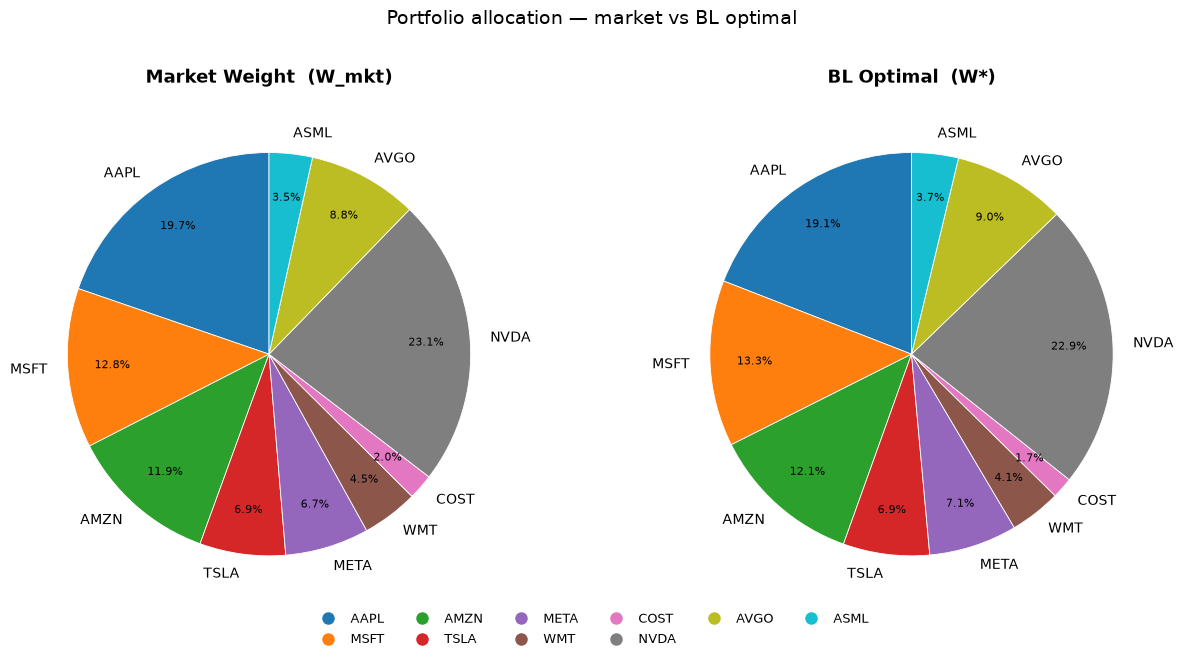

In [14]:
import matplotlib.pyplot as plt

fig, axes = plt.subplots(1, 2, figsize=(13, 6))

cmap   = plt.get_cmap("tab20")
colors = [cmap(i / len(tickers)) for i in range(len(tickers))]

def _pie(ax, weights, title):
    labels = [t if w * 100 >= 1.5 else "" for t, w in zip(tickers, weights)]
    wedges, _, autotexts = ax.pie(
        weights, labels=labels, colors=colors,
        autopct=lambda p: f"{p:.1f}%" if p >= 1.5 else "",
        startangle=90, pctdistance=0.78,
        wedgeprops=dict(linewidth=0.6, edgecolor="white"),
    )
    for at in autotexts:
        at.set_fontsize(8)
    ax.set_title(title, fontweight="bold", fontsize=13, pad=14)

_pie(axes[0], w_mkt,         "Market Weight  (W_mkt)")
_pie(axes[1], res["w_star"], f"BL Optimal  (W*)")

handles = [plt.Line2D([0], [0], marker="o", color="w",
           markerfacecolor=colors[i], markersize=10, label=t)
           for i, t in enumerate(tickers)]
fig.legend(handles=handles, loc="lower center", ncol=6,
           bbox_to_anchor=(0.5, -0.06), fontsize=9, frameon=False)
plt.suptitle("Portfolio allocation — market vs BL optimal", fontsize=14, y=1.02)
plt.tight_layout()
plt.show()

  ✅  QQQ: 4143 daily bars


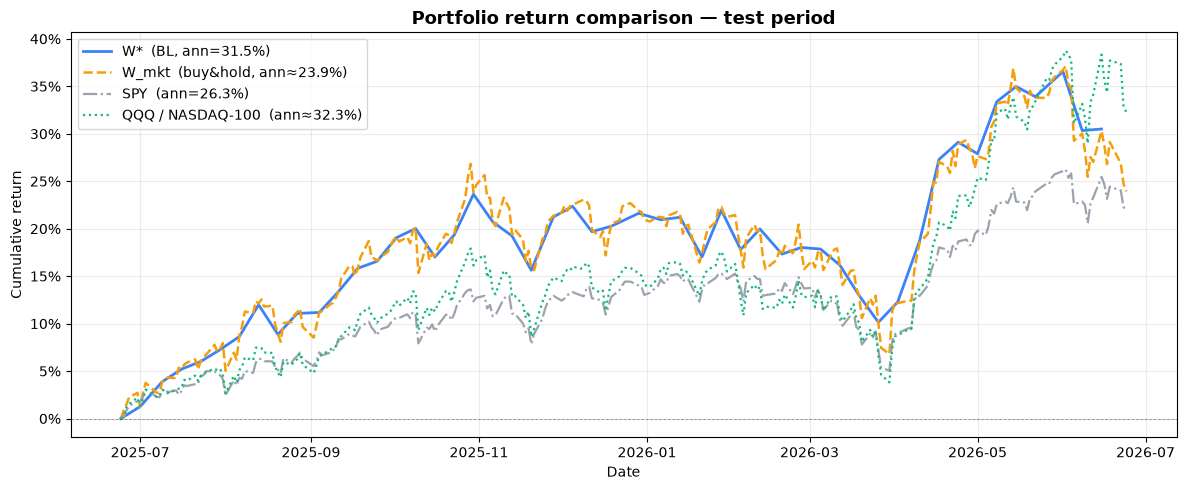

,ann_return,ann_vol,sharpe,max_drawdown
BL+model (W*),0.3150,0.1773,1.4940,-0.1091
SPY buy&hold,0.2627,0.1137,1.8700,-0.0698
NASDAQ-100 (QQQ),0.3243,0.1789,1.5331,-0.1196


In [ ]:
import matplotlib.pyplot as plt
import matplotlib.ticker as mticker

# ── fetch QQQ (NASDAQ-100) ───────────────────────────────────────────────────
qqq_raw   = fetch_data.download_prices("QQQ", C.DATA_START, C.DATA_END)
qqq_close = qqq_raw["close"] if qqq_raw is not None else None

t0 = pd.Timestamp(bt["test_start_date"]).normalize()

# ── W* equity (from backtest, 5-day rebalance steps) ─────────────────────────
eq_wstar = bt["strategy_equity"]

# ── W_mkt: daily buy-and-hold over test window, same tickers ─────────────────
panel_test  = panel[panel.index >= t0]
daily_rets  = panel_test.pct_change().fillna(0)
wmkt_ret    = (daily_rets * w_mkt).sum(axis=1)
eq_wmkt     = (1 + wmkt_ret).cumprod()
eq_wmkt     = eq_wmkt / eq_wmkt.iloc[0]

# ── SPY equity (normalised) ───────────────────────────────────────────────────
if bench_close is not None:
    bench_idx = pd.DatetimeIndex(bench_close.index).normalize()
    bench_s   = bench_close.copy(); bench_s.index = bench_idx
    spy_test  = bench_s[bench_s.index >= t0]
    eq_spy    = spy_test / spy_test.iloc[0]
else:
    eq_spy = None

# ── QQQ equity (normalised) ───────────────────────────────────────────────────
if qqq_close is not None:
    qqq_idx  = pd.DatetimeIndex(qqq_close.index).normalize()
    qqq_s    = qqq_close.copy(); qqq_s.index = qqq_idx
    qqq_test = qqq_s[qqq_s.index >= t0]
    eq_qqq   = qqq_test / qqq_test.iloc[0]
else:
    eq_qqq = None

# ── plot ──────────────────────────────────────────────────────────────────────
fig, ax = plt.subplots(figsize=(12, 5))

ax.plot(eq_wstar.index, (eq_wstar - 1) * 100,
        lw=2.0, color="#3b82f6", label=f"W*  (BL, ann={s['ann_return']:.1%})")
ax.plot(eq_wmkt.index,  (eq_wmkt  - 1) * 100,
        lw=1.8, color="#f59e0b", linestyle="--",
        label=f"W_mkt  (buy&hold, ann≈{float((eq_wmkt.iloc[-1])**(252/len(eq_wmkt))-1):.1%})")
if eq_spy is not None:
    ax.plot(eq_spy.index, (eq_spy - 1) * 100,
            lw=1.6, color="#9ca3af", linestyle="-.",
            label=f"SPY  (ann={b['ann_return']:.1%})" if b else "SPY")
if eq_qqq is not None:
    qqq_ann = float(eq_qqq.iloc[-1] ** (252 / max(len(eq_qqq), 1)) - 1)
    ax.plot(eq_qqq.index, (eq_qqq - 1) * 100,
            lw=1.6, color="#10b981", linestyle=":",
            label=f"QQQ / NASDAQ-100  (ann≈{qqq_ann:.1%})")

ax.axhline(0, color="black", lw=0.6, linestyle="--", alpha=0.4)
ax.yaxis.set_major_formatter(mticker.FormatStrFormatter("%.0f%%"))
ax.set_xlabel("Date"); ax.set_ylabel("Cumulative return")
ax.set_title("Portfolio return comparison — test period", fontweight="bold", fontsize=13)
ax.legend(fontsize=10, loc="upper left"); ax.grid(alpha=0.25)
plt.tight_layout(); plt.show()

if qqq_metrics:
    rows["NASDAQ-100 (QQQ)"] = qqq_metrics

metrics = pd.DataFrame(rows).T[["ann_return", "ann_vol", "sharpe", "max_drawdown"]]
display(metrics.round(4))

In [ ]:
# ── Skipped tickers summary ─────────────────────────────────────────────
if skipped:
    print("=" * 60)
    print(f"  ⚠️  Skipped tickers ({len(skipped)} excluded from model):")
    print(f"  {'Ticker':<8}  Reason")
    print("  " + "-" * 58)
    for t, reason in sorted(skipped.items()):
        print(f"  {t:<8}  {reason}")
    print(f"\n  → {len(skipped)} skipped · {len(stock_data)} used in model.")
else:
    print(f"  → All {len(TICKERS)} tickers used in model (none skipped).")


  → All 10 tickers used in model (none skipped).
